# Overview
In this notebook, we will build and train neural networks using [JAX](https://jax.readthedocs.io/). We will consider the following examples:

- MNIST dataset of handwritten digits
- Image reconstruction example

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
from jax import random, grad
import optax
from keras.datasets import mnist
from PIL import Image
import matplotlib.pyplot as plt
from skimage import data

## MNIST example of handwritten digits
The MNIST dataset is a standard machine learning benchmark containing 70,000 grayscale 28x28 pixel images of handwritten digits from zero to nine. 
It can be loaded directly through most deep learning libraries like `keras.datasets` or downloaded manually from [Yann LeCun's official website](http://yann.lecun.com/).

- 60,000 for training
- 10,000 for testing

In [2]:
# Load MNIST data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = x_train.reshape(-1, 28*28) / 255.0
x_test  = x_test.reshape(-1, 28*28) / 255.0

y_train = jax.nn.one_hot(y_train, 10)
y_test  = jax.nn.one_hot(y_test, 10)

x_train = jnp.array(x_train)
y_train = jnp.array(y_train)
x_test  = jnp.array(x_test)
y_test  = jnp.array(y_test)

# Initialization 
def init_mnist_params(key):
    return {
        "W1": random.normal(key, (784, 128)) * 0.01,
        "b1": jnp.zeros(128),
        "W2": random.normal(key, (128, 10)) * 0.01,
        "b2": jnp.zeros(10),
    }

def mnist_forward(params, x):
    # can change activation function
    h = jax.nn.relu(x @ params["W1"] + params["b1"])
    return h @ params["W2"] + params["b2"]

def mnist_loss(params, x, y):
    logits = mnist_forward(params, x)
    return optax.softmax_cross_entropy(logits, y).mean()

# Training method (Gradient Descent)
    # can change lr and steps
def train_gd(params, lr=0.1, steps=200):
    losses = []
    #speeds up the full-batch gradient calculation
    @jax.jit
    def update(p, x, y):
        g = grad(mnist_loss)(p, x, y)
        p = jax.tree_util.tree_map(lambda w, dw: w - lr * dw, p, g)
        return p, mnist_loss(p, x, y)

    for step in range(steps):
        params, loss_val = update(params, x_train, y_train)
        losses.append(loss_val)

        if step % 50 == 0:
            print(f"Iteration {step}, Loss: {loss_val:.4f}")
        
    return params, jnp.array(losses)

# Accuracy method
def mnist_accuracy(params, x, y):
    logits = mnist_forward(params, x)
    preds = jnp.argmax(logits, axis=1)
    labels = jnp.argmax(y, axis=1)
    correct = jnp.sum(preds == labels)
    accuracy = correct / x.shape[0]
    return int(correct), float(accuracy)

# Run training
mnist_params = init_mnist_params(random.PRNGKey(1))
gd_params, gd_train_loss = train_gd(mnist_params)

# Compute accuracy
gd_correct, gd_acc = mnist_accuracy(gd_params, x_test, y_test)

print(f"accuracy:   {gd_correct} / {len(x_test)}   ({gd_acc*100:.2f}%)")

Iteration 0, Loss: 2.3017
Iteration 50, Loss: 1.9509
Iteration 100, Loss: 0.9197
Iteration 150, Loss: 0.6177
accuracy:   8716 / 10000   (87.16%)


Alternatively, instead of testing the trained model on the prescribed testset, one could also just test their own handwritten digits.
The code below converts a handwritten digit picture from .jpg format into data that can be given to our trained NN.

[[ 2.0342228  -4.3327594   1.7915055   1.3930694  -1.8072331   1.6628966
  -0.6042712  -0.6570632   1.269841   -0.88070834]]


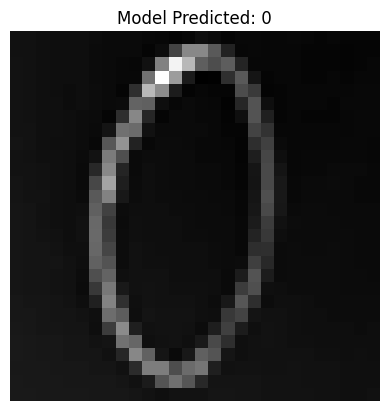

In [3]:
# Load the image and convert to grayscale ('L' mode)
image_path = "../0.jpg"  # Change this to your file's name
img = Image.open(image_path).convert('L')

# Resize to 28x28 pixels
img = img.resize((28, 28))

# Convert to a numpy array
img_array = np.array(img)

# INVERT COLORS 
img_array = 255 - img_array 
#img_array = np.where(img_array>130, 255, img_array)

# Normalize pixel values to [0, 1] just like our training data
img_array = img_array / 255.0

# Reshape to match the network's input shape: (1 sample, 784 pixels)
x_custom = img_array.reshape(1, 784)
x_custom = jnp.array(x_custom)

# Predict using your trained gradient descent parameters
logits = mnist_forward(gd_params, x_custom)
prediction = jnp.argmax(logits, axis=1)[0]
print(logits)

# Visualize 
plt.imshow(img_array, cmap='gray')
plt.title(f"Model Predicted: {prediction}")
plt.axis('off')
plt.show()

## Image Reconstruction: Memorizing with Neural Networks
In this example, we use the famous "Cameraman" dataset to demonstrate how neural networks can reconstruct visual data. Instead of feeding an image *through* the network, we train the network to *become* the image.

We treat the image as a physical coordinate grid. 
- **The Input:** We feed the network just two numbers: the (X, Y) space coordinates of a single pixel. 
- **The Output:** The network predicts the grayscale brightness for that exact location. 
- **The Reconstruction:** By guessing the brightness for every coordinate and correcting its mistakes via *optimization algorithms*, the original image is slowly memorized into the network's hidden layers. To reconstruct the final image, we simply ask the network to predict the color for every coordinate on a blank canvas.

Iteration 0, Loss: 0.0834
Iteration 500, Loss: 0.0216
Iteration 1000, Loss: 0.0191
Iteration 1500, Loss: 0.0175


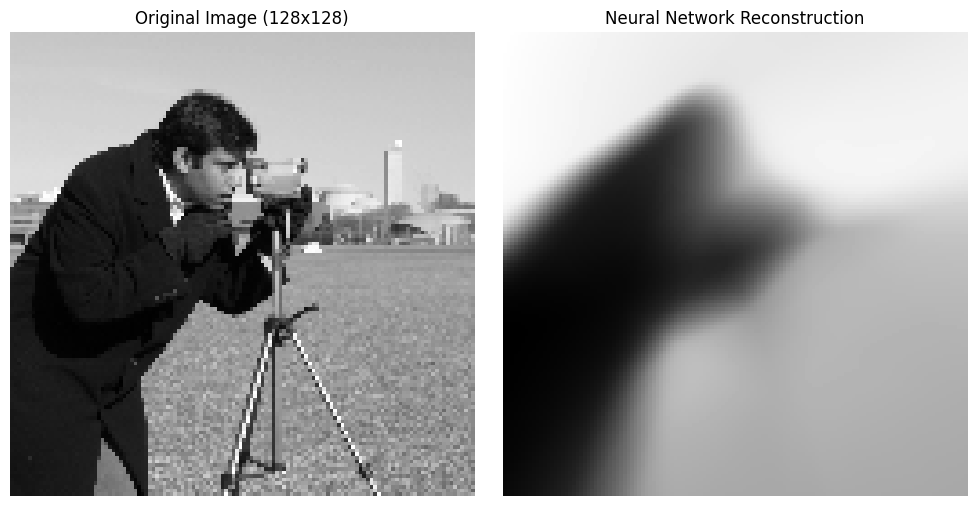

In [4]:
# Load the Cameraman
original_img = data.camera()

# Downsample it to 128x128 so it trains instantly
img = original_img[::4, ::4] / 255.0
H, W = img.shape

# Create the dataset: (X, Y) inputs -> Pixel brightness output
x_coords = np.linspace(-1, 1, W)
y_coords = np.linspace(-1, 1, H)
xx, yy = np.meshgrid(x_coords, y_coords)

# Flatten into lists of inputs (coordinates) and outputs (pixels)
X_data = jnp.array(np.c_[xx.ravel(), yy.ravel()], dtype=jnp.float32)
Y_data = jnp.array(img.ravel().reshape(-1, 1), dtype=jnp.float32)


# Initialization and model
def init_camera_params(key):
    # 4 hidden layers of 128 neurons
    keys = random.split(key, 5)
    return {
        "W1": random.normal(keys[0], (2, 128)) * 0.1,  "b1": jnp.zeros(128),
        "W2": random.normal(keys[1], (128, 128)) * 0.1, "b2": jnp.zeros(128),
        "W3": random.normal(keys[2], (128, 128)) * 0.1, "b3": jnp.zeros(128),
        "W4": random.normal(keys[3], (128, 128)) * 0.1, "b4": jnp.zeros(128),
        "W5": random.normal(keys[4], (128, 1)) * 0.1,   "b5": jnp.zeros(1),
    }

def camera_forward(params, x):
    h = jax.nn.relu(x @ params["W1"] + params["b1"])
    h = jax.nn.relu(h @ params["W2"] + params["b2"])
    h = jax.nn.relu(h @ params["W3"] + params["b3"])
    h = jax.nn.relu(h @ params["W4"] + params["b4"])
    # Use sigmoid at the end to ensure the output brightness is strictly between 0 and 1
    return jax.nn.sigmoid(h @ params["W5"] + params["b5"])

# Mean Squared Error for regression
def mse_loss(params, x, y):
    preds = camera_forward(params, x)
    return jnp.mean((preds - y) ** 2)


# Training
def train_camera_gd(params, lr=0.5, steps=2000):
    @jax.jit
    def update(p, x, y):
        loss_val, g = jax.value_and_grad(mse_loss)(p, x, y)
        p = jax.tree_util.tree_map(lambda w, dw: w - lr * dw, p, g)
        return p, loss_val

    losses = []
    for step in range(steps):
        params, loss_val = update(params, X_data, Y_data)
        if step % 500 == 0:
            print(f"Iteration {step}, Loss: {loss_val:.4f}")
            
    return params

# Run it
cam_params = init_camera_params(random.PRNGKey(7))
 # can change lr and steps
trained_cam_params = train_camera_gd(cam_params, lr=0.5, steps=2000)

# Visualize the Reconstruction
predicted_pixels = camera_forward(trained_cam_params, X_data)
reconstructed_img = predicted_pixels.reshape(H, W)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img, cmap='gray')
axes[0].set_title("Original Image (128x128)")
axes[0].axis('off')

axes[1].imshow(reconstructed_img, cmap='gray')
axes[1].set_title("Neural Network Reconstruction")
axes[1].axis('off')

plt.tight_layout()
plt.show()